## lab03_24i2551

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap

df = pd.read_csv("Sample - Superstore.csv", encoding="latin1")

# cleaning
df.columns = df.columns.str.strip()
df = df.drop_duplicates()
df = df.dropna(subset=["Order Date","Sales","Profit","Discount","Region","Sub-Category","Category"])
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y", errors="coerce")
df = df.dropna(subset=["Order Date"])          # drop any dates that failed to parse
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df["Profit"] = pd.to_numeric(df["Profit"], errors="coerce")
df["Discount"] = pd.to_numeric(df["Discount"], errors="coerce")
df = df.dropna(subset=["Sales","Profit","Discount"])  # drop rows where numeric coercion failed
df = df[(df["Sales"] > 0) & (df["Discount"].between(0,1))]  # remove impossible values

df.to_csv("Superstore_cleaned.csv", index=False)
df.shape

(9994, 21)

## Task 1

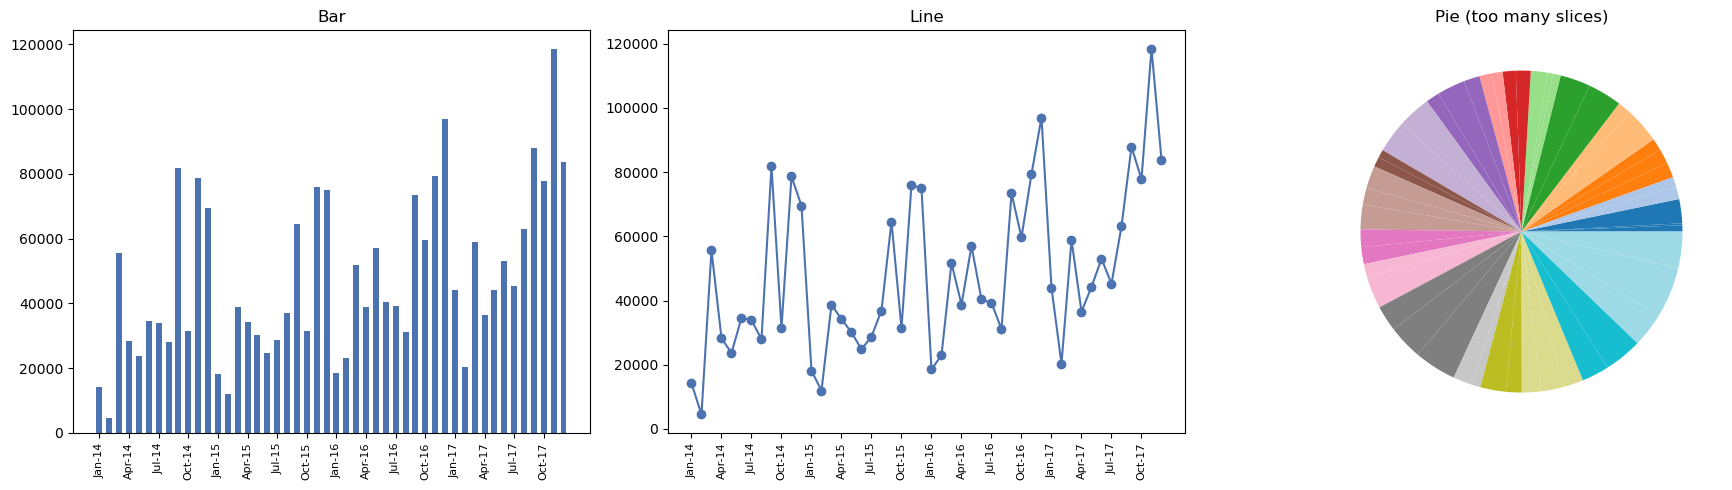

In [10]:
monthly = df.set_index("Order Date").resample("ME")["Sales"].sum()
labels = monthly.index.strftime("%b-%y")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].bar(labels, monthly.values, color="#4C72B0", width=0.6)
axes[0].set_title("Bar")
axes[0].set_xticks(range(0, len(labels), 3))              # every 3rd label
axes[0].set_xticklabels(labels[::3], rotation=90, fontsize=8)

axes[1].plot(labels, monthly.values, marker="o", color="#4C72B0")
axes[1].set_title("Line")
axes[1].set_xticks(range(0, len(labels), 3))
axes[1].set_xticklabels(labels[::3], rotation=90, fontsize=8)

axes[2].pie(monthly.values, labels=None, colors=plt.cm.tab20(np.linspace(0,1,len(monthly))))
axes[2].set_title("Pie (too many slices)")

plt.tight_layout()
plt.show()

Line chart shows the trend best (ordered points + connecting slope make direction/rate of change visible). Pie hides it as 24 slices with close values, no ordering, no time axis.

## Task 2

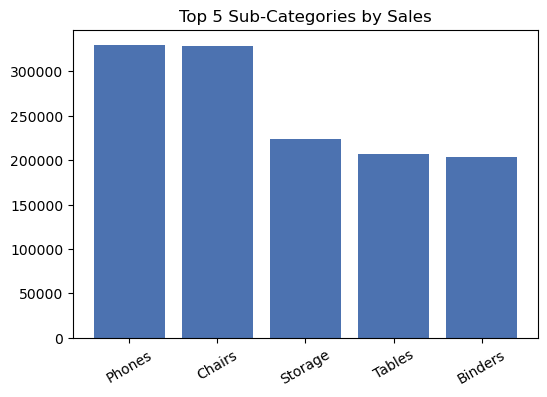

In [11]:
#2a. Compare total sales across top 5 sub-categories -> Bar
top5 = df.groupby("Sub-Category")["Sales"].sum().nlargest(5)
plt.figure(figsize=(6,4))
plt.bar(top5.index, top5.values, color="#4C72B0")
plt.title("Top 5 Sub-Categories by Sales")
plt.xticks(rotation=30)
plt.show()


Bar fits: discrete categories, precise magnitude comparison. Pie/radar would obscure small differences between the top 5 since areas/angles are harder to judge than aligned bar lengths.

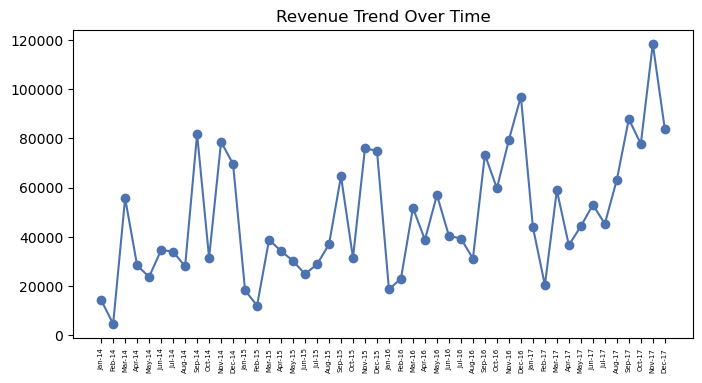

In [18]:
#2b. Revenue trend over time -> Line (reuse Task 1 monthly data)
plt.figure(figsize=(8,4))
plt.plot(labels, monthly.values, marker="o", color="#4C72B0")
plt.title("Revenue Trend Over Time")
plt.xticks(rotation=90, fontsize=5)
plt.show()


Line fits: continuous time axis makes trend/slope visible. A bar chart with this many periods would be cluttered and trend-reading would require comparing 24 bar heights instead of a single slope.

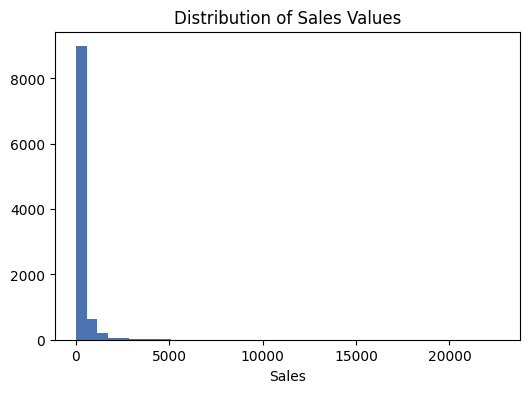

In [5]:

# 2c. Distribution of order-line sales values -> Histogram
plt.figure(figsize=(6,4))
plt.hist(df["Sales"], bins=40, color="#4C72B0")
plt.title("Distribution of Sales Values")
plt.xlabel("Sales")
plt.show()


Histogram fits: shows shape/spread/skew of raw values. A bar-of-averages would collapse the whole distribution into one number and hide the skew/outliers.

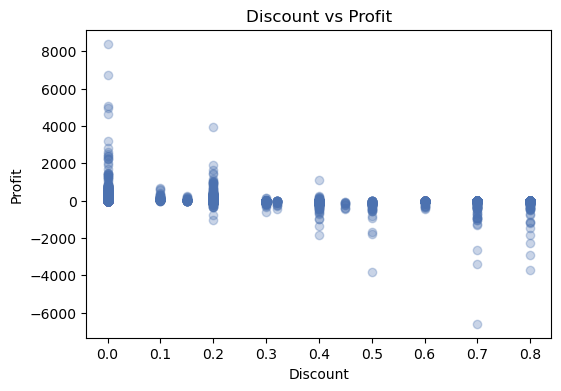

In [20]:
# 2d. Relationship between discount and profit -> Scatter
plt.figure(figsize=(6,4))
plt.scatter(df["Discount"], df["Profit"], alpha=0.3, color="#4C72B0")
plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.show()

Scatter fits: reveals correlation/spread between two continuous variables. A line chart would force a false ordering on discount values and mask the actual point-cloud relationship.

## Task 3: Recoloring with proper palettes

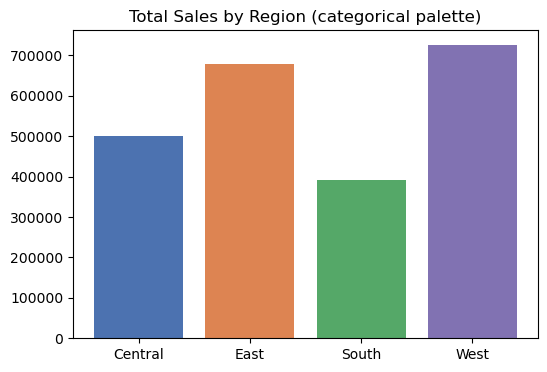

In [21]:
# 3a. Region sales - categorical palette (distinct hues, cap ~8)
region_sales = df.groupby("Region")["Sales"].sum()
categorical_palette = ["#4C72B0", "#DD8452", "#55A868", "#8172B2"]  # <=8 distinguishable hues

plt.figure(figsize=(6,4))
plt.bar(region_sales.index, region_sales.values, color=categorical_palette[:len(region_sales)])
plt.title("Total Sales by Region (categorical palette)")
plt.show()


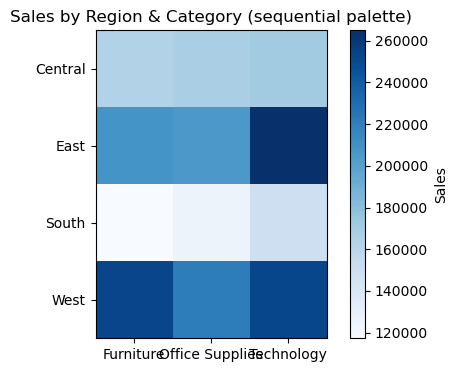

In [24]:
# 3b. Region x Category - heatmap with sequential palette (one hue, light->dark)
pivot = df.pivot_table(index="Region", columns="Category", values="Sales", aggfunc="sum")
plt.figure(figsize=(6,4))
plt.imshow(pivot.values, cmap="Blues")
plt.xticks(range(len(pivot.columns)), pivot.columns)
plt.yticks(range(len(pivot.index)), pivot.index)
plt.colorbar(label="Sales")
plt.title("Sales by Region & Category (sequential palette)")
plt.show()

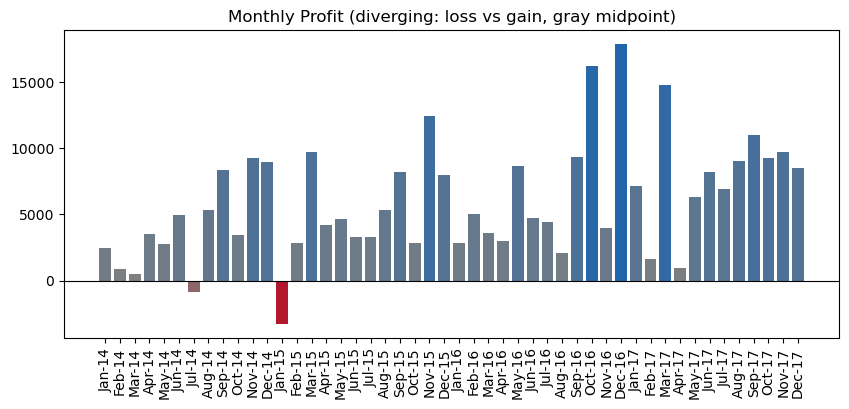

In [23]:

# 3c. Monthly profit - diverging color chart (crosses zero, gray midpoint)
monthly_profit = df.set_index("Order Date").resample("ME")["Profit"].sum()
diverging_cmap = LinearSegmentedColormap.from_list("div", ["#B2182B", "#808080", "#2166AC"])
norm = mcolors.TwoSlopeNorm(vmin=monthly_profit.min(), vcenter=0, vmax=monthly_profit.max())
colors = diverging_cmap(norm(monthly_profit.values))

plt.figure(figsize=(10,4))
plt.bar(monthly_profit.index.strftime("%b-%y"), monthly_profit.values, color=colors)
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=90)
plt.title("Monthly Profit (diverging: loss vs gain, gray midpoint)")
plt.show()

## Task 4: WCAG contrast + colorblind check

In [10]:

def relative_luminance(hex_color):
    rgb = mcolors.to_rgb(hex_color)
    def lin(c):
        return c/12.92 if c <= 0.03928 else ((c+0.055)/1.055)**2.4
    r,g,b = [lin(c) for c in rgb]
    return 0.2126*r + 0.7152*g + 0.0722*b

def contrast_ratio(c1, c2):
    l1, l2 = relative_luminance(c1), relative_luminance(c2)
    l1, l2 = max(l1,l2), min(l1,l2)
    return (l1+0.05)/(l2+0.05)

test_colors = categorical_palette + ["#08306B", "#B2182B", "#808080", "#2166AC"]  # Task 3 colors
background = "#FFFFFF"
for c in test_colors:
    ratio = contrast_ratio(c, background)
    status = "PASS" if ratio >= 4.5 else "FAIL"
    print(f"{c}: {ratio:.2f}  {status}")


#4C72B0: 4.84  PASS
#DD8452: 2.80  FAIL
#55A868: 2.92  FAIL
#8172B2: 4.21  FAIL
#08306B: 12.76  PASS
#B2182B: 6.87  PASS
#808080: 3.95  FAIL
#2166AC: 5.90  PASS


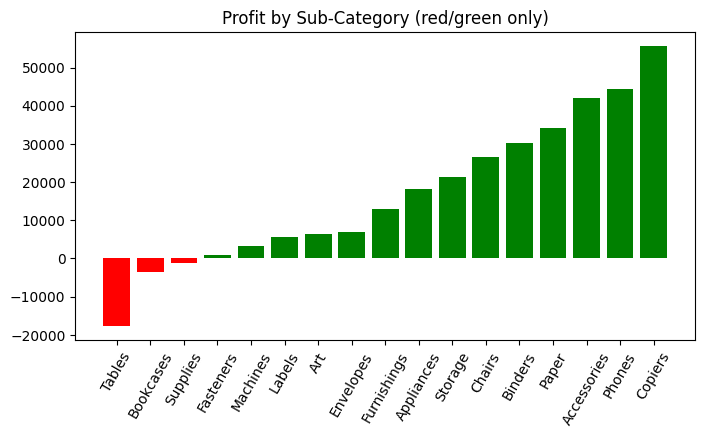

In [11]:

# 4b. Profit by sub-category, loss vs gain, red/green only (deliberately non-accessible)
subcat_profit = df.groupby("Sub-Category")["Profit"].sum().sort_values()
colors_rg = ["red" if v < 0 else "green" for v in subcat_profit.values]

plt.figure(figsize=(8,4))
plt.bar(subcat_profit.index, subcat_profit.values, color=colors_rg)
plt.xticks(rotation=60)
plt.title("Profit by Sub-Category (red/green only)")
plt.show()


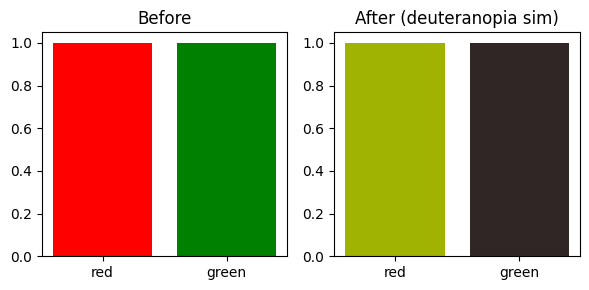

In [12]:

# simple deuteranopia simulation (Machado-style approximation)
sim_matrix = np.array([
    [0.625, 0.375, 0.0],
    [0.70,  0.30,  0.0],
    [0.0,   0.30,  0.70]
])

def simulate_deuteranopia(hex_color):
    rgb = np.array(mcolors.to_rgb(hex_color))
    sim = sim_matrix @ rgb
    return np.clip(sim, 0, 1)

fig, axes = plt.subplots(1,2, figsize=(6,3))
axes[0].bar(["red","green"], [1,1], color=["red","green"])
axes[0].set_title("Before")
sim_colors = [simulate_deuteranopia("red"), simulate_deuteranopia("green")]
axes[1].bar(["red","green"], [1,1], color=sim_colors)
axes[1].set_title("After (deuteranopia sim)")
plt.tight_layout()
plt.show()


Simulation: red and green bars become nearly indistinguishable in tone -> fails colorblind accessibility.

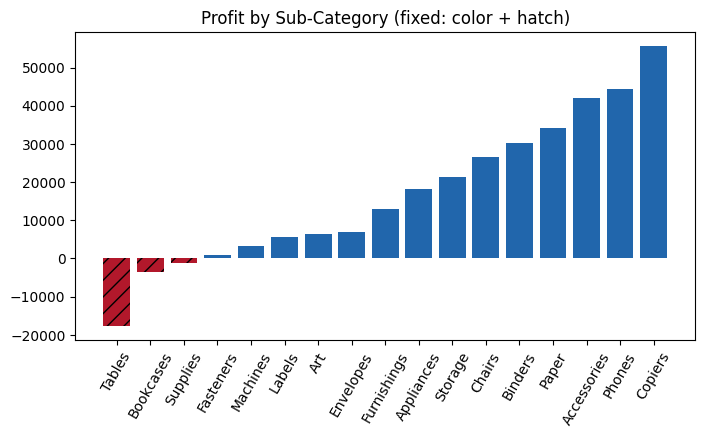

In [13]:

# fixed version: safe palette + hatching so distinction survives simulation
colors_safe = ["#B2182B" if v < 0 else "#2166AC" for v in subcat_profit.values]
hatches = ["//" if v < 0 else "" for v in subcat_profit.values]

fig, ax = plt.subplots(figsize=(8,4))
bars = ax.bar(subcat_profit.index, subcat_profit.values, color=colors_safe)
for bar, h in zip(bars, hatches):
    bar.set_hatch(h)
plt.xticks(rotation=60)
plt.title("Profit by Sub-Category (fixed: color + hatch)")
plt.show()
# Alt text: "Bar chart of total profit by sub-category; loss sub-categories shown in red with diagonal hatching, gains shown in blue, sorted ascending by profit."


## Task 5: Misleading visualizations (3 distortions)

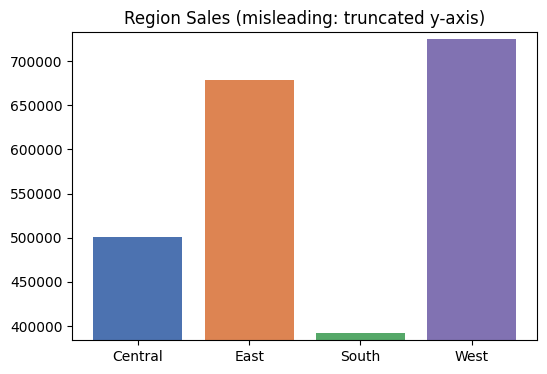

In [14]:

# 1. Truncated y-axis on region sales chart
plt.figure(figsize=(6,4))
plt.bar(region_sales.index, region_sales.values, color=categorical_palette[:len(region_sales)])
plt.ylim(region_sales.min()*0.98, region_sales.max()*1.01)
plt.title("Region Sales (misleading: truncated y-axis)")
plt.show()
# Caption: truncated y-axis exaggerates small differences between regions.


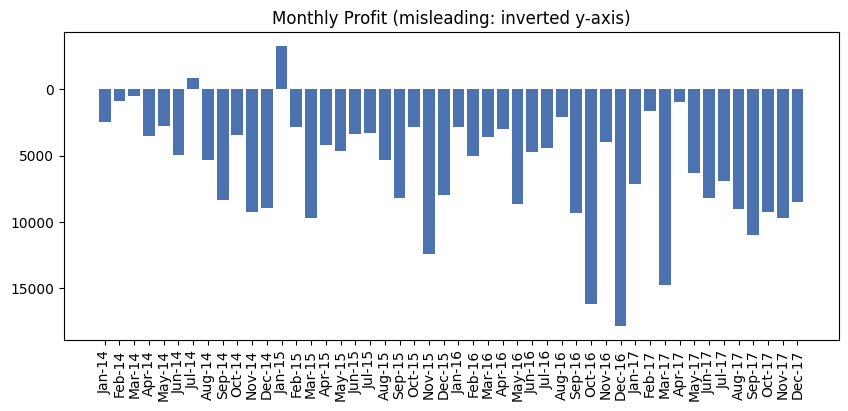

In [15]:

# 2. Inverted y-axis on monthly profit
plt.figure(figsize=(10,4))
plt.bar(monthly_profit.index.strftime("%b-%y"), monthly_profit.values, color="#4C72B0")
plt.gca().invert_yaxis()
plt.xticks(rotation=90)
plt.title("Monthly Profit (misleading: inverted y-axis)")
plt.show()
# Caption: inverted y-axis makes growing profit visually look like a decline.


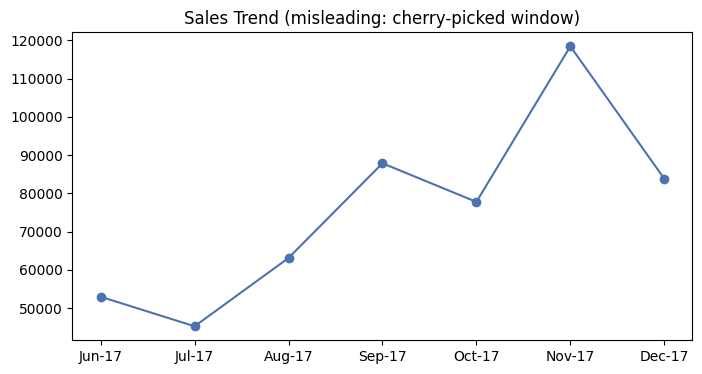

In [16]:

# 3. Cherry-picked date window on monthly sales, hides overall trend
window = monthly["2017-06":"2017-12"]
plt.figure(figsize=(8,4))
plt.plot(window.index.strftime("%b-%y"), window.values, marker="o", color="#4C72B0")
plt.title("Sales Trend (misleading: cherry-picked window)")
plt.show()
# Caption: showing only Jun-Dec 2017 hides the surrounding dips/rises in the full series and implies steady growth.


## Task 6: Is discounting hurting profit?

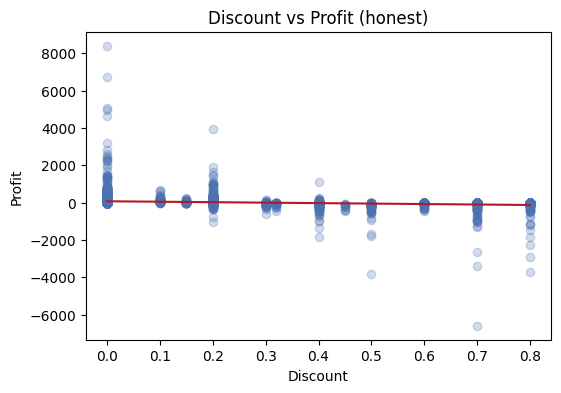

In [17]:

# Honest version: scatter with trend line
z = np.polyfit(df["Discount"], df["Profit"], 1)
trend = np.poly1d(z)
x_line = np.linspace(df["Discount"].min(), df["Discount"].max(), 100)

plt.figure(figsize=(6,4))
plt.scatter(df["Discount"], df["Profit"], alpha=0.25, color="#4C72B0")
plt.plot(x_line, trend(x_line), color="#B2182B")
plt.title("Discount vs Profit (honest)")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.show()


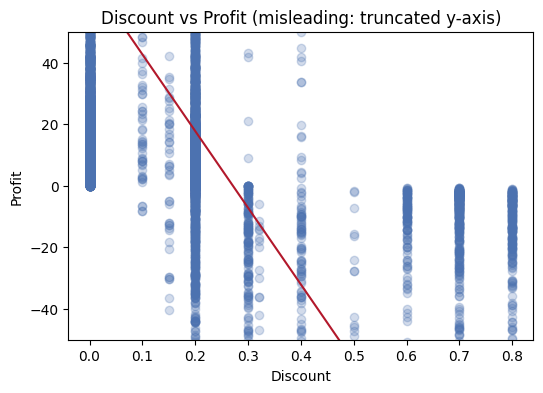

In [18]:

# Misleading version: truncated y-axis hides losses, exaggerates recovery at low discount
plt.figure(figsize=(6,4))
plt.scatter(df["Discount"], df["Profit"], alpha=0.25, color="#4C72B0")
plt.plot(x_line, trend(x_line), color="#B2182B")
plt.ylim(-50, 50)
plt.title("Discount vs Profit (misleading: truncated y-axis)")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.show()


**Chart type**: scatter (correlation between two continuous variables). **Color**: single categorical hue for points, red trend line for emphasis (not red/green pair). **Accessibility check**: trend line + point cloud don't rely on color alone; contrast of #4C72B0 and #B2182B against white both pass 4.5:1. The honest chart shows profit dropping sharply and turning negative past ~20% discount; the misleading version truncates the y-axis to -50/50, hiding the full magnitude of losses at high discount.